<a href="https://colab.research.google.com/github/peter-adepoju/math-neuro-ml/blob/main/lesson3/Lesson3_Teaching_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **MAMBA: Mathematical Sciences for Brain Data**
## Lesson 3 — Matrices as Neural Recordings, Datasets, and Connectivity

**Course:** MAMBA: Mathematical Sciences for Brain Data\
**Week:** Week 1 — Linear Algebra I\
**Lesson:** Lesson 3\
**Notebook type:** Teaching notebook

> *"A recording session, a machine-learning dataset, and a wiring diagram of a neural circuit are all the same kind of object: a table of numbers with a meaning attached to every row and every column."*

---

### From one vector to many

Lesson 1 treated one population response as a vector. Lesson 2 compared two vectors. A real experiment produces *many*: one population vector per trial, one feature vector per observation. Stack them as rows and you get a **matrix**.

This lesson is about reading, storing and preparing matrices correctly: what the rows and columns mean, how to transpose and index them, which special matrices appear in neuroscience, the difference between elementwise and matrix operations, and the preprocessing steps (centring, scaling, missing values, metadata) that decide whether an analysis is right before any mathematics happens.

### Import Dependencies

In [1]:
# SETUP CELL
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from plotly.subplots import make_subplots

RNG = np.random.default_rng(42)

# The same colourblind-conscious palette and markers as Lessons 1 and 2.
PALETTE = ['#0072B2', '#D55E00', '#009E73', '#CC79A7', '#E69F00', '#56B4E9']
MARKERS = ['o', 's', '^', 'D', 'v', 'P']

print("Setup complete.")

Setup complete.


### Interactive and animated plotting tools

As in Lessons 1 and 2, each static figure is followed by a **Plotly version** that you can zoom, pan, hover over, and save. Hover over any heatmap cell to see its row, column and value.

In [2]:
# INTERACTIVE/ANIMATION SETUP
import sys
import plotly.io as pio

# Colab picks its own renderer. Elsewhere (Jupyter, VS Code), load plotly.js with each figure,
# as Colab does, so every saved figure displays on its own.
if 'google.colab' not in sys.modules:
    pio.renderers.default = 'notebook_connected'

# Background gridlines off in the template used throughout.
pio.templates['plotly_white'].layout.xaxis.showgrid = False
pio.templates['plotly_white'].layout.yaxis.showgrid = False

PLOTLY_MARKERS = ['circle', 'square', 'triangle-up', 'diamond', 'triangle-down', 'cross']

PLOTLY_CONFIG = {
    'displaylogo': False,
    'responsive': True,
    'scrollZoom': True,
    'toImageButtonOptions': {
        'format': 'png',
        'scale': 2,
    },
}

def padded_limits(values, fraction=0.08, minimum_padding=1.0):
    # Return stable axis limits with a small padding around the data.
    values = np.asarray(values, dtype=float)
    lo = float(np.nanmin(values))
    hi = float(np.nanmax(values))
    span = hi - lo
    pad = minimum_padding if span == 0 else fraction * span
    return lo - pad, hi + pad

def play_pause_and_slider(labels, prefix):
    # Play/Pause buttons and a frame slider, as used in Lessons 1 and 2.
    buttons = [dict(
        type='buttons', showactive=False, x=0.0, y=-0.12, xanchor='left', yanchor='top',
        buttons=[
            dict(label='Play', method='animate', args=[None, {'frame': {'duration': 350, 'redraw': True}, 'transition': {'duration': 0}, 'fromcurrent': True}]),
            dict(label='Pause', method='animate', args=[[None], {'frame': {'duration': 0, 'redraw': False}, 'mode': 'immediate'}]),
        ],
    )]
    sliders = [dict(
        active=0, currentvalue={'prefix': prefix}, pad={'t': 50},
        steps=[
            dict(label=str(lab), method='animate', args=[[str(k)], {'mode': 'immediate', 'frame': {'duration': 0, 'redraw': True}, 'transition': {'duration': 0}}])
            for k, lab in enumerate(labels)
        ],
    )]
    return buttons, sliders

print('Interactive plotting and animation tools are ready.')

Interactive plotting and animation tools are ready.


# **Motivation: one recording session as one table**

Three neurons are recorded on four trials. On each trial the population has a state vector, exactly as in Lesson 1:

| | N1 | N2 | N3 |
|---|---|---|---|
| trial 1 (stimulus 1) | 12 | 4 | 19 |
| trial 2 (stimulus 2) | 50 | 8 | 33 |
| trial 3 (stimulus 1) | 14 | 5 | 21 |
| trial 4 (stimulus 2) | 48 | 9 | 30 |

Stacking the four state vectors as rows gives one object with **4 rows and 3 columns**. Each row is one trial; each column is one neuron. That is a matrix.

In [3]:
R = np.array([[12.0,  4.0, 19.0],
              [50.0,  8.0, 33.0],
              [14.0,  5.0, 21.0],
              [48.0,  9.0, 30.0]])   # spikes/s, shape (n_trials, n_neurons) = (4, 3)

print("R shape:", R.shape, " (n_trials, n_neurons), units: spikes/s")
print("Trial 2 (row index 1)  :", R[1], "spikes/s")
print("Neuron N3 (column 2)   :", R[:, 2], "spikes/s")
print("Mean population vector :", R.mean(axis=0), "spikes/s (average over trials)")

R shape: (4, 3)  (n_trials, n_neurons), units: spikes/s
Trial 2 (row index 1)  : [50.  8. 33.] spikes/s
Neuron N3 (column 2)   : [19. 33. 21. 30.] spikes/s
Mean population vector : [31.    6.5  25.75] spikes/s (average over trials)


Machine learning stores data the same way. A dataset of houses is a matrix with one row per house and one column per feature. A **design matrix** of shape (n_observations, n_features) is the input to almost every model you will meet.

In [4]:
X_houses = np.array([[1416.0, 3.0, 40.0],
                     [1530.0, 2.0,  5.0],
                     [1380.0, 5.0, 80.0]])   # shape (n_houses, n_features) = (3, 3)
feature_names = ['size (sq ft)', 'bedrooms', 'age (years)']

print("X_houses shape:", X_houses.shape, " (n_observations, n_features)")
print("House 2       :", ", ".join(f"{n} = {v:g}" for n, v in zip(feature_names, X_houses[1])))

X_houses shape: (3, 3)  (n_observations, n_features)
House 2       : size (sq ft) = 1530, bedrooms = 2, age (years) = 5


The numbers alone are not the data. A matrix only means something together with two lists you must keep beside it: **what each row is** (which trial, which condition) and **what each column is** (which neuron, which unit). Much of this lesson is about keeping those three things together.

# **Part 1: Matrix Notation, Entries, and Shape**

A matrix with $m$ rows and $n$ columns is written

$$
\mathbf{X} = \begin{pmatrix}
x_{11} & x_{12} & \cdots & x_{1n} \\
x_{21} & x_{22} & \cdots & x_{2n} \\
\vdots & \vdots & \ddots & \vdots \\
x_{m1} & x_{m2} & \cdots & x_{mn}
\end{pmatrix} \in \mathbb{R}^{m \times n}.
$$

- $x_{ij}$ is the **entry** in row $i$, column $j$. Row index first, always.
- The **shape** (or dimensions) is $m \times n$: rows first, then columns.
- In NumPy the entry $x_{ij}$ is `X[i-1, j-1]`, because Python counts from 0.

We now build a bigger recording: 6 neurons recorded on 24 trials, each trial either a **left** or a **right** stimulus, presented in random order.

In [5]:
neuron_ids = np.array(['N1', 'N2', 'N3', 'N4', 'N5', 'N6'])
neuron_areas = np.array(['V1', 'V1', 'V1', 'PPC', 'PPC', 'M1'])   # brain area of each neuron
n_trials, n_neurons = 24, len(neuron_ids)

conditions = RNG.choice(np.array(['left', 'right']), size=n_trials)   # one label per trial, random order
mean_rate = {'left':  np.array([20.0,  5.0, 12.0, 80.0,  8.0, 15.0]),
             'right': np.array([ 6.0, 18.0, 12.0, 40.0, 25.0, 15.0])}   # spikes/s per neuron
noise_sd = np.array([2.5, 2.5, 2.5, 8.0, 3.0, 2.0])                    # trial-to-trial variability, spikes/s

rates = np.array([mean_rate[c] + RNG.normal(0.0, noise_sd) for c in conditions])
rates = np.clip(rates, 0, None).round(1)   # firing rates cannot be negative

print("rates shape:", rates.shape, " (n_trials, n_neurons), units: spikes/s")
print("Entry x_{3,4} (trial 3, neuron N4) = rates[2, 3] =", rates[2, 3], "spikes/s")
print("First three trial labels:", conditions[:3])

rates shape: (24, 6)  (n_trials, n_neurons), units: spikes/s
Entry x_{3,4} (trial 3, neuron N4) = rates[2, 3] = 42.9 spikes/s
First three trial labels: ['left' 'right' 'right']


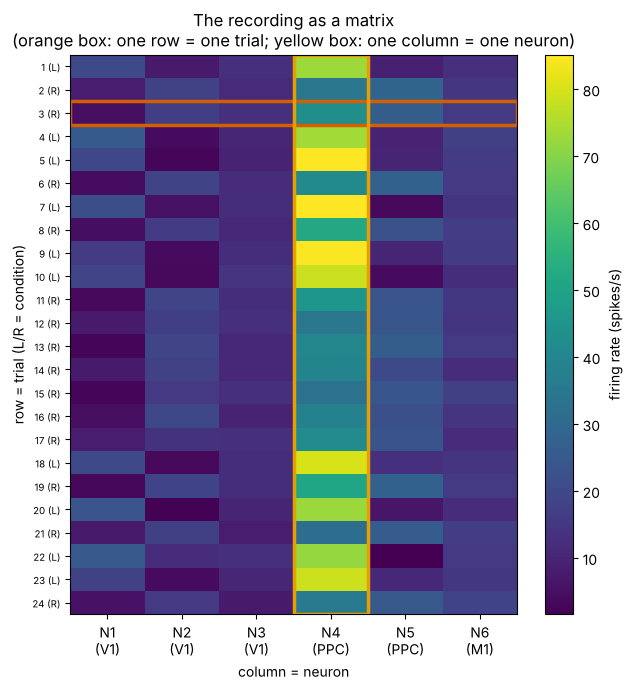

In [6]:
# A matrix drawn as a heatmap: one row per trial, one column per neuron
fig, ax = plt.subplots(figsize=(6.5, 7))
im = ax.imshow(rates, aspect='auto', cmap='viridis')
ax.set_xticks(range(n_neurons)); ax.set_xticklabels([f'{n}\n({a})' for n, a in zip(neuron_ids, neuron_areas)])
ax.set_yticks(range(n_trials)); ax.set_yticklabels([f'{i+1} ({c[0].upper()})' for i, c in enumerate(conditions)], fontsize=7)
ax.add_patch(plt.Rectangle((-0.5, 1.5), n_neurons, 1, fill=False, edgecolor=PALETTE[1], lw=2.5))      # one row
ax.add_patch(plt.Rectangle((2.5, -0.5), 1, n_trials, fill=False, edgecolor=PALETTE[4], lw=2.5))       # one column
ax.set_xlabel('column = neuron'); ax.set_ylabel('row = trial (L/R = condition)')
ax.set_title('The recording as a matrix\n(orange box: one row = one trial; yellow box: one column = one neuron)')
fig.colorbar(im, ax=ax, label='firing rate (spikes/s)')
plt.tight_layout()
plt.show()

#### Interactive version

In [7]:
trial_labels = [f'trial {i+1} ({c})' for i, c in enumerate(conditions)]
fig_interactive = go.Figure(go.Heatmap(
    z=rates, x=list(neuron_ids), y=trial_labels, colorscale='Viridis',
    colorbar=dict(title='spikes/s'),
    hovertemplate='%{y}<br>neuron %{x}<br>rate = %{z:.1f} spikes/s<extra></extra>',
))
fig_interactive.update_yaxes(autorange='reversed')
fig_interactive.update_layout(title='The recording as a matrix (hover a cell)',
                              xaxis_title='column = neuron', yaxis_title='row = trial',
                              template='plotly_white', width=620, height=700)
fig_interactive.show(config=PLOTLY_CONFIG)

**Question:** the heatmap shows a column that is much brighter than the rest. Which neuron is it, and is that because it carries more information, or only because it fires faster? Keep the question in mind until Part 7.

# **Part 2: Rows, Columns, and Axes**

A matrix can be read two ways, and both are Lesson 1 vectors:

- **Row $i$** is a population state: all neurons on one trial. Shape `(n_neurons,)`.
- **Column $j$** is one neuron's responses across all trials. Shape `(n_trials,)`.

NumPy calls the row direction **axis 0** and the column direction **axis 1**. A function applied *along* an axis collapses that axis:

| Code | Collapses | Result shape | Meaning |
|---|---|---|---|
| `rates.mean(axis=0)` | the trials | `(n_neurons,)` | mean population vector |
| `rates.mean(axis=1)` | the neurons | `(n_trials,)` | each trial's average rate across neurons |

A useful way to remember it: **the axis you name is the one that disappears.**

In [8]:
trial_2 = rates[1]            # row: shape (6,)
neuron_N4 = rates[:, 3]       # column: shape (24,)
print("Row (trial 2)     :", trial_2, " shape", trial_2.shape)
print("Column (neuron N4):", neuron_N4[:6], "...  shape", neuron_N4.shape)

mean_population = rates.mean(axis=0)   # average over trials
trial_average = rates.mean(axis=1)     # average over neurons
print("\nrates.mean(axis=0):", mean_population.round(1), " shape", mean_population.shape, "-> one value per neuron")
print("rates.mean(axis=1):", trial_average[:6].round(1), "...  shape", trial_average.shape, "-> one value per trial")

Row (trial 2)     : [ 8.2 17.9 11.5 34.6 28.7 14.7]  shape (6,)
Column (neuron N4): [73.1 34.6 42.9 73.5 85.2 41.7] ...  shape (24,)

rates.mean(axis=0): [11.9 12.2 11.6 56.1 17.7 15.1]  shape (6,) -> one value per neuron
rates.mean(axis=1): [22.8 19.3 20.  23.4 24.  20. ] ...  shape (24,) -> one value per trial


Combining rows with a **boolean mask** selects trials by their label. This is how a condition-average is computed: keep the rows whose label matches, then average down the rows.

In [9]:
is_left = conditions == 'left'                 # shape (24,), True/False per trial
mean_left = rates[is_left].mean(axis=0)        # shape (6,)
mean_right = rates[~is_left].mean(axis=0)

print(f"{is_left.sum()} left trials, {(~is_left).sum()} right trials")
print("Mean left  population vector:", mean_left.round(1), "spikes/s")
print("Mean right population vector:", mean_right.round(1), "spikes/s")

10 left trials, 14 right trials
Mean left  population vector: [20.9  5.  12.  78.4  7.9 14.8] spikes/s
Mean right population vector: [ 5.5 17.4 11.4 40.2 24.7 15.4] spikes/s


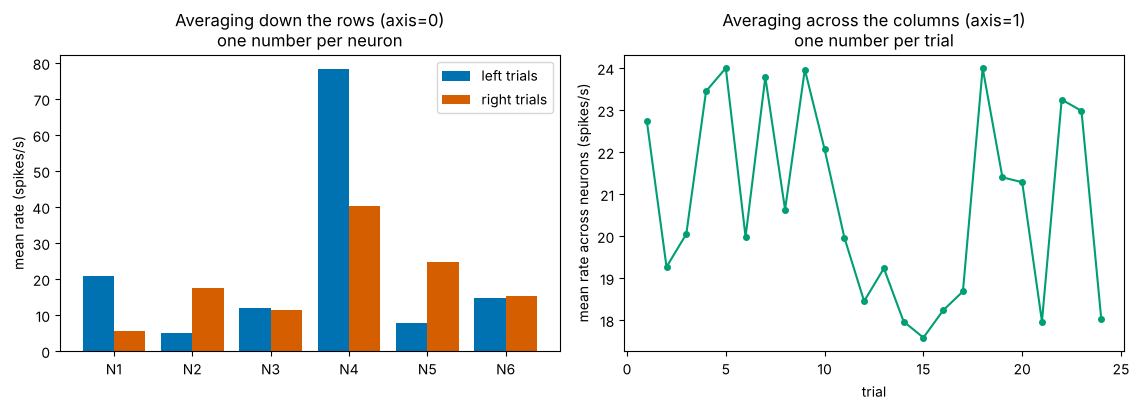

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
x_pos = np.arange(n_neurons)

ax = axes[0]
ax.bar(x_pos - 0.2, mean_left, width=0.4, color=PALETTE[0], label='left trials')
ax.bar(x_pos + 0.2, mean_right, width=0.4, color=PALETTE[1], label='right trials')
ax.set_xticks(x_pos); ax.set_xticklabels(neuron_ids)
ax.set_ylabel('mean rate (spikes/s)'); ax.set_title('Averaging down the rows (axis=0)\none number per neuron')
ax.legend()

ax = axes[1]
ax.plot(np.arange(1, n_trials + 1), trial_average, '-o', color=PALETTE[2], ms=4)
ax.set_xlabel('trial'); ax.set_ylabel('mean rate across neurons (spikes/s)')
ax.set_title('Averaging across the columns (axis=1)\none number per trial')
plt.tight_layout()
plt.show()

#### Animation: each row is a point in state space

Step through the trials. The highlighted row of the matrix (left) is plotted as one point in the N1–N4 plane (right). The matrix *is* a cloud of points, one per trial.

In [11]:
# INTERACTIVE ANIMATION -- one matrix row at a time becomes one point in state space
cond_colour = np.where(is_left, PALETTE[0], PALETTE[1])
fig_rows = make_subplots(rows=1, cols=2, column_widths=[0.45, 0.55], horizontal_spacing=0.14,
                         subplot_titles=('Recording matrix (current row boxed)', 'Rows as points: N1 vs N4'))
fig_rows.add_trace(go.Heatmap(z=rates, x=list(neuron_ids), y=list(range(1, n_trials + 1)), colorscale='Viridis',
                              showscale=False, hovertemplate='trial %{y}, %{x}: %{z:.1f} spikes/s<extra></extra>'), row=1, col=1)
fig_rows.add_trace(go.Scatter(x=[-0.5, n_neurons - 0.5, n_neurons - 0.5, -0.5, -0.5], y=[0.5, 0.5, 1.5, 1.5, 0.5],
                              mode='lines', line=dict(color=PALETTE[1], width=4), name='current row', showlegend=False), row=1, col=1)
fig_rows.add_trace(go.Scatter(x=rates[:1, 0], y=rates[:1, 3], mode='markers', name='trials so far',
                              marker=dict(color=list(cond_colour[:1]), size=11, line=dict(color='black', width=1))), row=1, col=2)
fig_rows.frames = [
    go.Frame(name=str(k), traces=[1, 2], data=[
        go.Scatter(x=[-0.5, n_neurons - 0.5, n_neurons - 0.5, -0.5, -0.5], y=[k + 0.5, k + 0.5, k + 1.5, k + 1.5, k + 0.5]),
        go.Scatter(x=rates[:k + 1, 0], y=rates[:k + 1, 3], marker=dict(color=list(cond_colour[:k + 1]), size=11, line=dict(color='black', width=1))),
    ])
    for k in range(n_trials)
]
buttons, sliders = play_pause_and_slider([f'{k + 1} ({conditions[k]})' for k in range(n_trials)], prefix='trial = ')
fig_rows.update_yaxes(autorange='reversed', title_text='trial', row=1, col=1)
fig_rows.update_xaxes(title_text='N1 rate (spikes/s)', range=list(padded_limits(rates[:, 0])), row=1, col=2)
fig_rows.update_yaxes(title_text='N4 rate (spikes/s)', range=list(padded_limits(rates[:, 3])), row=1, col=2)
fig_rows.update_layout(title='Each row of the matrix is one population state (blue = left, orange = right)',
                       template='plotly_white', width=1000, height=560, updatemenus=buttons, sliders=sliders)
fig_rows.show(config=PLOTLY_CONFIG)

# **Part 3: The Transpose**

The **transpose** $\mathbf{X}^{\mathsf T}$ flips a matrix across its main diagonal: rows become columns.

$$
(\mathbf{X}^{\mathsf T})_{ij} = x_{ji}, \qquad \mathbf{X}\in\mathbb{R}^{m\times n} \;\Longrightarrow\; \mathbf{X}^{\mathsf T}\in\mathbb{R}^{n\times m}.
$$

Transposing twice gives back the original: $(\mathbf{X}^{\mathsf T})^{\mathsf T} = \mathbf{X}$.

**Why it matters in practice.** Different tools store recordings differently. Many neuroscience toolboxes store **neurons × time** (one row per neuron); most machine-learning libraries expect **samples × features** (one row per observation). Transposing converts between them. Getting it wrong does not usually crash: it silently averages over the wrong axis.

In [12]:
rates_T = rates.T                         # shape (n_neurons, n_trials) = (6, 24)
print("rates  :", rates.shape, " (n_trials, n_neurons)")
print("rates.T:", rates_T.shape, " (n_neurons, n_trials)")
print("rates[2, 3] =", rates[2, 3], "  rates.T[3, 2] =", rates_T[3, 2], " (the same number)")
print("Transposing twice gives back the original?", np.array_equal(rates.T.T, rates))

# The silent bug: averaging 'over trials' on a neurons-by-trials array with the wrong axis
wrong = rates_T.mean(axis=0)      # averages over NEURONS, returns 24 numbers
right = rates_T.mean(axis=1)      # averages over TRIALS, returns 6 numbers
print("\nOn the (6, 24) array: mean(axis=0) has shape", wrong.shape, " <- wrong axis, no error raised")
print("                       mean(axis=1) has shape", right.shape, " <- one value per neuron")

rates  : (24, 6)  (n_trials, n_neurons)
rates.T: (6, 24)  (n_neurons, n_trials)
rates[2, 3] = 42.9   rates.T[3, 2] = 42.9  (the same number)
Transposing twice gives back the original? True

On the (6, 24) array: mean(axis=0) has shape (24,)  <- wrong axis, no error raised
                       mean(axis=1) has shape (6,)  <- one value per neuron


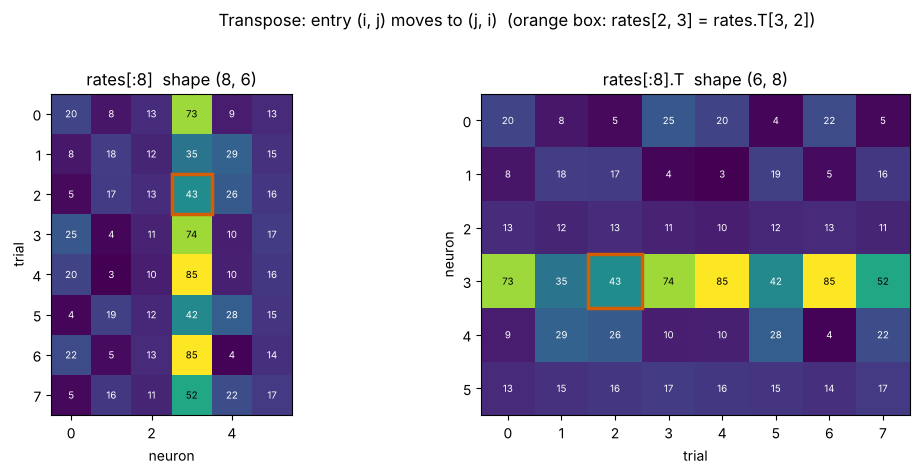

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), gridspec_kw={'width_ratios': [1, 2.4]})
for ax, M, title, xl, yl in [
    (axes[0], rates[:8], 'rates[:8]  shape (8, 6)', 'neuron', 'trial'),
    (axes[1], rates[:8].T, 'rates[:8].T  shape (6, 8)', 'trial', 'neuron'),
]:
    ax.imshow(M, cmap='viridis', aspect='equal')
    ax.set_title(title); ax.set_xlabel(xl); ax.set_ylabel(yl)
    for (i, j), val in np.ndenumerate(M):
        ax.text(j, i, f'{val:.0f}', ha='center', va='center', fontsize=7, color='white' if val < 50 else 'black')
axes[0].add_patch(plt.Rectangle((2.5, 1.5), 1, 1, fill=False, edgecolor=PALETTE[1], lw=2.5))
axes[1].add_patch(plt.Rectangle((1.5, 2.5), 1, 1, fill=False, edgecolor=PALETTE[1], lw=2.5))
fig.suptitle('Transpose: entry (i, j) moves to (j, i)  (orange box: rates[2, 3] = rates.T[3, 2])', y=1.02)
plt.tight_layout()
plt.show()

# **Part 4: Special Matrices**

A few matrices have names because they appear constantly.

| Matrix | Definition | Where you meet it |
|---|---|---|
| **Square** | $m = n$ | similarity, distance and connectivity matrices |
| **Zero** $\mathbf{0}$ | every entry is 0 | a starting point; "no connections" |
| **Identity** $\mathbf{I}_n$ | 1 on the diagonal, 0 elsewhere | "change nothing" (Lesson 4) |
| **Diagonal** | zero off the diagonal | one gain or variance per neuron |
| **Symmetric** | $\mathbf{A}^{\mathsf T} = \mathbf{A}$, i.e. $a_{ij} = a_{ji}$ | distances, similarities, undirected networks |
| **Sparse** | most entries are 0 | large connectivity matrices |

The **main diagonal** is the entries $a_{11}, a_{22}, \dots$ where the row index equals the column index.

In [14]:
I5 = np.eye(5)                                          # identity, shape (5, 5)
gains = np.diag([2.0, 1.0, 0.5, 1.0, 3.0])              # diagonal: one gain per neuron

# A symmetric matrix you already know: distances between trials (Lesson 1), first 8 trials
first = rates[:8]
D = np.sqrt(((first[:, None, :] - first[None, :, :]) ** 2).sum(axis=2))   # shape (8, 8), spikes/s

print("Identity:\n", I5)
print("\nDiagonal entries of the gain matrix:", np.diag(gains))
print("\nDistance matrix D is symmetric? ", np.allclose(D, D.T))
print("Its diagonal (distance of each trial to itself):", np.diag(D).round(1))

Identity:
 [[1. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0.]
 [0. 0. 1. 0. 0.]
 [0. 0. 0. 1. 0.]
 [0. 0. 0. 0. 1.]]

Diagonal entries of the gain matrix: [2.  1.  0.5 1.  3. ]

Distance matrix D is symmetric?  True
Its diagonal (distance of each trial to itself): [0. 0. 0. 0. 0. 0. 0. 0.]


The line computing `D` uses broadcasting to subtract every trial from every other trial at once: `first[:, None, :]` has shape `(8, 1, 6)` and `first[None, :, :]` has shape `(1, 8, 6)`, so their difference has shape `(8, 8, 6)`. You do not need to write code like this yet; the point is the result, which is symmetric because $d(\mathbf{u},\mathbf{v}) = d(\mathbf{v},\mathbf{u})$.

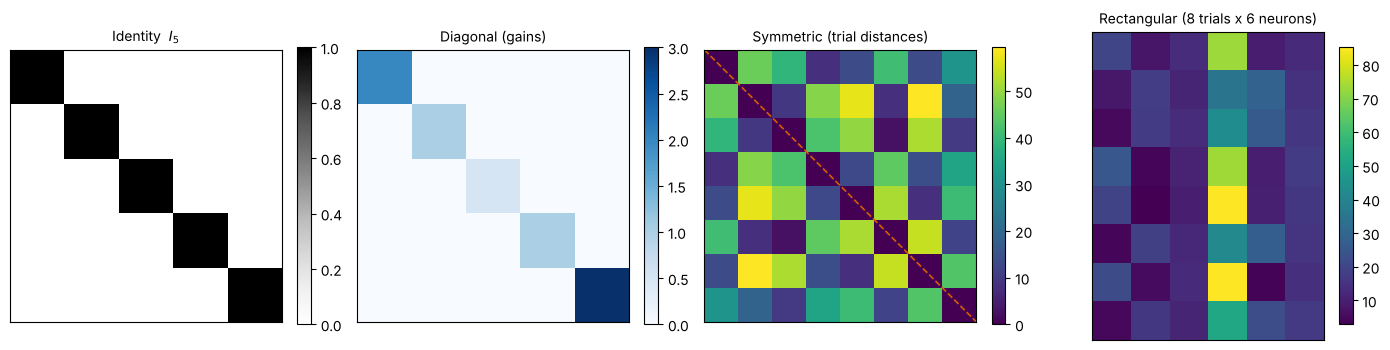

In [15]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6))
panels = [(I5, 'Identity  $I_5$', 'Greys'), (gains, 'Diagonal (gains)', 'Blues'),
          (D, 'Symmetric (trial distances)', 'viridis'), (rates[:8], 'Rectangular (8 trials x 6 neurons)', 'viridis')]
for ax, (M, title, cmap) in zip(axes, panels):
    im = ax.imshow(M, cmap=cmap)
    ax.set_title(title, fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
    fig.colorbar(im, ax=ax, fraction=0.046)
axes[2].plot([-0.5, 7.5], [-0.5, 7.5], color=PALETTE[1], lw=1.2, ls='--')
plt.tight_layout()
plt.show()

In the symmetric matrix, the dashed main diagonal is a mirror: the upper triangle is a reflection of the lower one. A symmetric matrix is always square.

**Question:** is the matrix of cosine similarities you built in Lesson 2 symmetric? What is on its diagonal?

# **Part 5: Connectivity as an Adjacency Matrix**

A neural circuit can be stored as a square **adjacency matrix** $\mathbf{A}$, one row and one column per neuron. The entry $a_{ij}$ is the strength of the connection between two neurons, with 0 for no connection. Positive means excitatory, negative inhibitory.

**The convention must be stated.** In this course

$$a_{ij} = \text{weight of the connection } \textbf{from } \text{neuron } j \textbf{ to } \text{neuron } i,$$

so **row $i$ lists the inputs of neuron $i$** and **column $j$ lists the outputs of neuron $j$**. This "row = target, column = source" convention is the one that makes Lesson 4 work out ($\mathbf{A}\mathbf{r}$ gives each neuron's total input). Some software uses the opposite. Always check.

In [16]:
circuit = ['N1', 'N2', 'N3', 'N4', 'N5', 'N6']
A = np.zeros((6, 6))                 # A[target, source]
A[1, 0] = 0.8    # N1 -> N2 (excitatory)
A[2, 1] = 0.6    # N2 -> N3
A[0, 2] = -0.5   # N3 -> N1 (inhibitory feedback)
A[3, 0] = 0.4    # N1 -> N4
A[4, 3] = 0.9    # N4 -> N5
A[3, 4] = 0.9    # N5 -> N4 (reciprocal pair)
A[5, 4] = 0.7    # N5 -> N6

in_strength = A.sum(axis=1)                 # row sums: total input to each neuron
out_strength = A.sum(axis=0)                # column sums: total output of each neuron
n_connections = np.count_nonzero(A)
density = n_connections / A.size

print("A shape:", A.shape, " (target neuron, source neuron)")
print("Total input  per neuron (row sums)   :", ", ".join(f"{n} {v:+.1f}" for n, v in zip(circuit, in_strength)))
print("Total output per neuron (column sums):", ", ".join(f"{n} {v:+.1f}" for n, v in zip(circuit, out_strength)))
print(f"{n_connections} connections out of {A.size} possible: density = {density:.2f}")
print("Symmetric?", np.allclose(A, A.T), " (a directed circuit usually is not)")

A shape: (6, 6)  (target neuron, source neuron)
Total input  per neuron (row sums)   : N1 -0.5, N2 +0.8, N3 +0.6, N4 +1.3, N5 +0.9, N6 +0.7
Total output per neuron (column sums): N1 +1.2, N2 +0.6, N3 -0.5, N4 +0.9, N5 +1.6, N6 +0.0
7 connections out of 36 possible: density = 0.19
Symmetric? False  (a directed circuit usually is not)


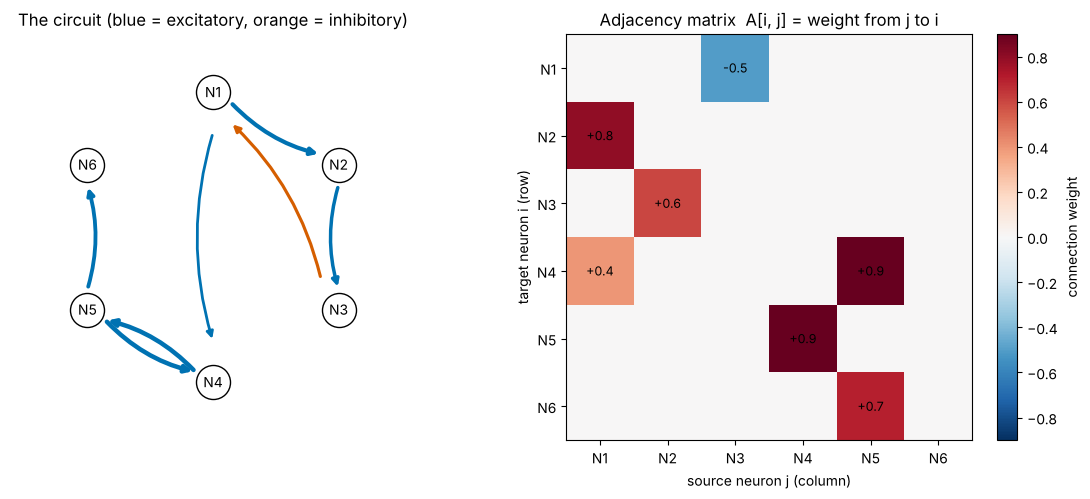

In [17]:
# Draw the circuit and its matrix side by side
angles = np.linspace(np.pi / 2, np.pi / 2 - 2 * np.pi, 6, endpoint=False)
pos = np.stack([np.cos(angles), np.sin(angles)], axis=1)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 5))
ax = axes[0]
for i in range(6):
    for j in range(6):
        if A[i, j] != 0:                                      # arrow from source j to target i
            colour = PALETTE[0] if A[i, j] > 0 else PALETTE[1]
            ax.annotate('', xy=pos[i] * 0.86 + pos[j] * 0.14, xytext=pos[j] * 0.86 + pos[i] * 0.14,
                        arrowprops=dict(arrowstyle='-|>', color=colour, lw=1 + 2.5 * abs(A[i, j]),
                                        connectionstyle='arc3,rad=0.15'))
for k, name in enumerate(circuit):
    ax.scatter(*pos[k], s=600, color='white', edgecolor='black', zorder=3)
    ax.text(*pos[k], name, ha='center', va='center', zorder=4)
ax.set_xlim(-1.4, 1.4); ax.set_ylim(-1.4, 1.4); ax.set_aspect('equal'); ax.axis('off')
ax.set_title('The circuit (blue = excitatory, orange = inhibitory)')

ax = axes[1]
lim = np.abs(A).max()
im = ax.imshow(A, cmap='RdBu_r', vmin=-lim, vmax=lim)
ax.set_xticks(range(6)); ax.set_xticklabels(circuit); ax.set_yticks(range(6)); ax.set_yticklabels(circuit)
ax.set_xlabel('source neuron j (column)'); ax.set_ylabel('target neuron i (row)')
for (i, j), val in np.ndenumerate(A):
    if val != 0:
        ax.text(j, i, f'{val:+.1f}', ha='center', va='center', fontsize=9)
ax.set_title('Adjacency matrix  A[i, j] = weight from j to i')
fig.colorbar(im, ax=ax, fraction=0.046, label='connection weight')
plt.tight_layout()
plt.show()

#### Interactive version

In [18]:
hover = [[(f'{circuit[j]} -> {circuit[i]}: weight {A[i, j]:+.1f}' if A[i, j] != 0 else f'no connection {circuit[j]} -> {circuit[i]}')
          for j in range(6)] for i in range(6)]
fig_interactive = go.Figure(go.Heatmap(
    z=A, x=circuit, y=circuit, text=hover, hovertemplate='%{text}<extra></extra>',
    colorscale='RdBu', reversescale=True, zmid=0, colorbar=dict(title='weight'),
))
fig_interactive.update_yaxes(autorange='reversed', title='target neuron i (row)')
fig_interactive.update_xaxes(title='source neuron j (column)')
fig_interactive.update_layout(title='Adjacency matrix (hover a cell to read the connection)',
                              template='plotly_white', width=560, height=520)
fig_interactive.show(config=PLOTLY_CONFIG)

### Large networks are sparse

Real circuits are large and most pairs of neurons are not directly connected. A matrix with mostly zeros is **sparse**. Storing every zero wastes memory. `scipy.sparse` stores only the nonzero entries and their positions.

In [19]:
from scipy import sparse

n_big = 2000
p_connect = 0.01                                            # each directed pair connected with probability 1%
mask = RNG.random((n_big, n_big)) < p_connect
np.fill_diagonal(mask, False)                               # no self-connections
A_big = np.where(mask, RNG.normal(0.5, 0.1, size=(n_big, n_big)), 0.0)

A_sparse = sparse.csr_matrix(A_big)
dense_mb = A_big.nbytes / 1e6
sparse_mb = (A_sparse.data.nbytes + A_sparse.indices.nbytes + A_sparse.indptr.nbytes) / 1e6

print(f"Shape {A_big.shape}, nonzero entries: {A_sparse.nnz:,}  (density {A_sparse.nnz / A_big.size:.3%})")
print(f"Dense storage : {dense_mb:6.1f} MB")
print(f"Sparse storage: {sparse_mb:6.1f} MB")

Shape (2000, 2000), nonzero entries: 40,117  (density 1.003%)
Dense storage :   32.0 MB
Sparse storage:    0.5 MB


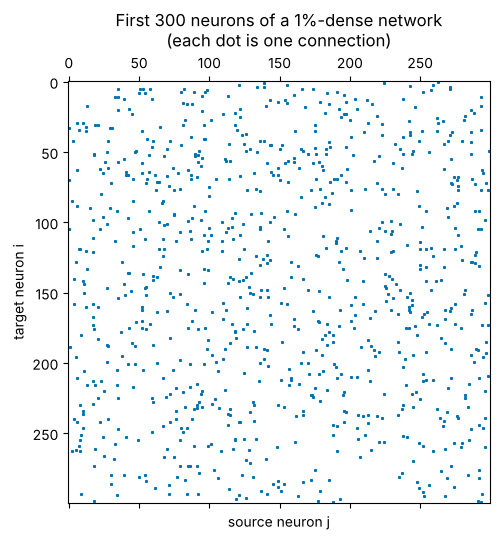

In [20]:
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.spy(A_sparse[:300, :300], markersize=1.2, color=PALETTE[0])
ax.set_title('First 300 neurons of a 1%-dense network\n(each dot is one connection)')
ax.set_xlabel('source neuron j'); ax.set_ylabel('target neuron i')
plt.tight_layout()
plt.show()

**Neuroscience context.** Connectomes, the wiring diagrams reconstructed from electron microscopy, are stored exactly like this. The *C. elegans* nervous system has about 300 neurons; the fruit-fly brain connectome has over 100 000 neurons and tens of millions of synapses, and would be impossible to store as a dense matrix.

# **Part 6: Elementwise Operations versus Matrix Operations**

Some operations treat a matrix as a grid of independent numbers and act **entry by entry**. They require matrices of the same shape (or shapes that broadcast):

$$
(\mathbf{A}+\mathbf{B})_{ij} = a_{ij}+b_{ij}, \qquad (c\mathbf{A})_{ij} = c\,a_{ij}, \qquad (\mathbf{A}\odot\mathbf{B})_{ij} = a_{ij}\,b_{ij}.
$$

The last one, the entry-by-entry product, is called the **Hadamard product** and is what NumPy's `*` computes.

Other operations treat a matrix as a whole. The most important, the **matrix product** written `@`, combines *rows of one with columns of the other* using dot products. Lesson 4 develops it fully; here we only need to see that `*` and `@` are different operations.

In [21]:
# Elementwise operations with a meaning
session_1 = rates[:4]                                      # 4 trials x 6 neurons, spikes/s
session_2 = rates[4:8]
average_session = (session_1 + session_2) / 2              # entry-by-entry average
counts_per_50ms = 0.05 * session_1                         # scalar multiple: spikes/s -> expected spikes in 50 ms

lesion = np.ones_like(A); lesion[:, 0] = 0.0               # silence every output of N1 (column 0)
A_lesioned = A * lesion                                    # Hadamard product: keep or zero each connection

print("Average of two sessions, shape", average_session.shape)
print("Expected spike counts in 50 ms, trial 1:", counts_per_50ms[0])
print("Connections remaining after lesioning N1's outputs:", np.count_nonzero(A_lesioned), "of", np.count_nonzero(A))

Average of two sessions, shape (4, 6)
Expected spike counts in 50 ms, trial 1: [1.01  0.39  0.66  3.655 0.455 0.655]
Connections remaining after lesioning N1's outputs: 5 of 7


**Broadcasting with a vector.** A vector of one value per neuron, shape `(6,)`, lines up with the *columns* of a `(n_trials, 6)` matrix and is applied to every row. That is how you subtract a per-neuron baseline or apply a per-neuron gain.

In [22]:
baseline = np.array([4.0, 4.0, 10.0, 30.0, 6.0, 14.0])      # spikes/s, one per neuron, shape (6,)
evoked = rates - baseline                                  # (24, 6) - (6,) -> (24, 6): each column shifted by its own baseline
print("rates[0]  :", rates[0])
print("evoked[0] :", evoked[0].round(1), "  (rates minus each neuron's baseline)")

# '*' versus '@' with the same weight vector
w = np.array([1.0, -1.0, 0.0, 0.05, -0.5, 0.0])           # one weight per neuron
elementwise = rates * w                                    # (24, 6) * (6,) -> (24, 6): every entry scaled
matrix_vector = rates @ w                                  # (24, 6) @ (6,) -> (24,): one dot product per trial
print("\nrates * w has shape", elementwise.shape, " (each entry multiplied by its neuron's weight)")
print("rates @ w has shape", matrix_vector.shape, "   (each ROW dotted with w: a weighted sum per trial)")
print("Row 0 check:", np.isclose(matrix_vector[0], rates[0] @ w), "-- the Lesson 2 dot product, once per row")

rates[0]  : [20.2  7.8 13.2 73.1  9.1 13.1]
evoked[0] : [16.2  3.8  3.2 43.1  3.1 -0.9]   (rates minus each neuron's baseline)

rates * w has shape (24, 6)  (each entry multiplied by its neuron's weight)
rates @ w has shape (24,)    (each ROW dotted with w: a weighted sum per trial)
Row 0 check: True -- the Lesson 2 dot product, once per row


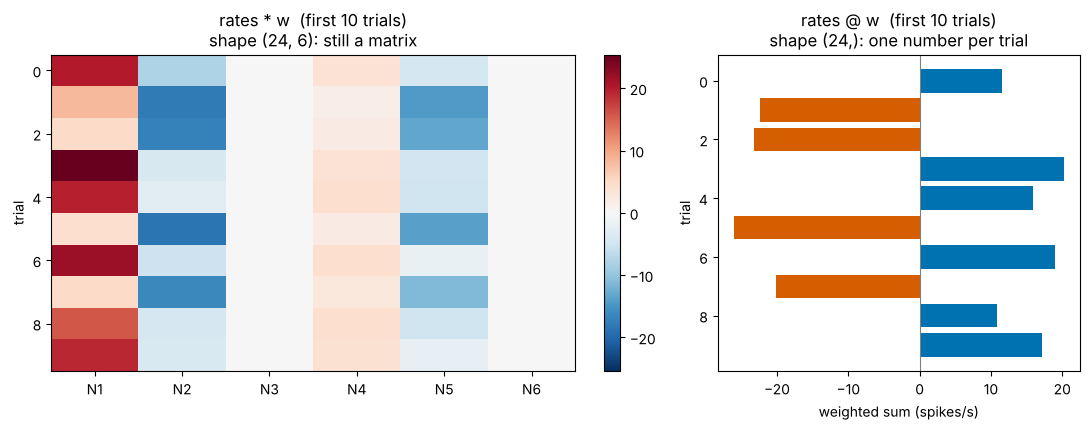

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), gridspec_kw={'width_ratios': [1.6, 1]})
ax = axes[0]
lim = np.abs(elementwise[:10]).max()
im = ax.imshow(elementwise[:10], cmap='RdBu_r', vmin=-lim, vmax=lim, aspect='auto')
ax.set_xticks(range(n_neurons)); ax.set_xticklabels(neuron_ids)
ax.set_ylabel('trial'); ax.set_title('rates * w  (first 10 trials)\nshape (24, 6): still a matrix')
fig.colorbar(im, ax=ax, fraction=0.046)
ax = axes[1]
ax.barh(np.arange(10), matrix_vector[:10], color=[PALETTE[0] if c == 'left' else PALETTE[1] for c in conditions[:10]])
ax.axvline(0, color='grey', lw=0.8)
ax.invert_yaxis(); ax.set_xlabel('weighted sum (spikes/s)'); ax.set_ylabel('trial')
ax.set_title('rates @ w  (first 10 trials)\nshape (24,): one number per trial')
plt.tight_layout()
plt.show()

The right panel separates left trials (blue) from right trials (orange) by sign, because the weights add N1 and subtract N2 and N5. `rates @ w` is the Lesson 2 weighted sum, computed for every trial at once.

> **Common pitfall.** Writing `*` when you meant `@` (or the reverse) often does *not* raise an error, because broadcasting finds a way to make the shapes fit. Check the result's shape every time: a weighted sum per trial must have shape `(n_trials,)`.

# **Part 7: Centring and Scaling**

Remember the question from Part 1: N4 is much brighter in the heatmap. Its rates are around 40–80 spikes/s, while N1, N2 and N5 vary between about 5 and 25. Any distance or similarity computed on raw rates will be dominated by N4, simply because its numbers are bigger (Lesson 1, Part 6).

Two standard fixes act **column by column**, i.e. on each neuron (each feature) separately. With $\mu_j$ the mean of column $j$ and $s_j$ its standard deviation:

$$
\textbf{centring: } \tilde{x}_{ij} = x_{ij} - \mu_j, \qquad\qquad \textbf{standardising (z-scoring): } z_{ij} = \frac{x_{ij} - \mu_j}{s_j}.
$$

After centring, every column has mean 0. After standardising, every column has mean 0 **and** standard deviation 1, and the units disappear: a value of $z_{ij} = 2$ means "two standard deviations above this neuron's average", whatever the neuron's typical rate.

In [24]:
mu = rates.mean(axis=0)              # shape (6,): one mean per neuron (column)
sd = rates.std(axis=0)               # shape (6,): one standard deviation per neuron
rates_centred = rates - mu           # broadcasting: each column minus its own mean
rates_z = (rates - mu) / sd          # z-scores: no units

print("Column means before        :", mu.round(1))
print("Column means after centring:", rates_centred.mean(axis=0).round(10) + 0.0)
print("Column SDs after z-scoring :", rates_z.std(axis=0).round(10) + 0.0)

Column means before        : [11.9 12.2 11.6 56.1 17.7 15.1]
Column means after centring: [0. 0. 0. 0. 0. 0.]
Column SDs after z-scoring : [1. 1. 1. 1. 1. 1.]


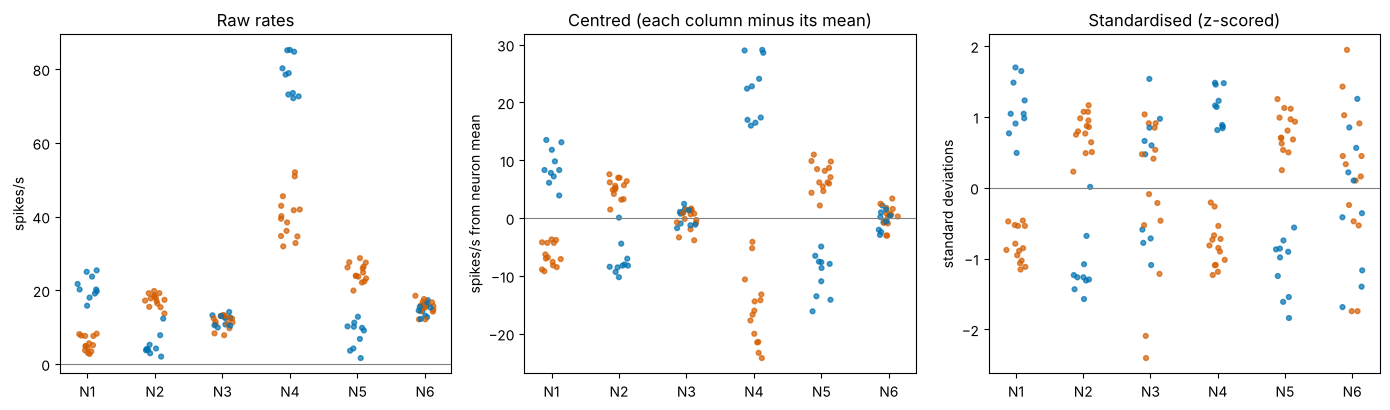

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, M, title, ylab in [(axes[0], rates, 'Raw rates', 'spikes/s'),
                           (axes[1], rates_centred, 'Centred (each column minus its mean)', 'spikes/s from neuron mean'),
                           (axes[2], rates_z, 'Standardised (z-scored)', 'standard deviations')]:
    for j in range(n_neurons):
        jitter = RNG.uniform(-0.15, 0.15, size=n_trials)
        ax.scatter(np.full(n_trials, j) + jitter, M[:, j], s=12, alpha=0.7,
                   c=[PALETTE[0] if c == 'left' else PALETTE[1] for c in conditions])
    ax.axhline(0, color='grey', lw=0.8)
    ax.set_xticks(range(n_neurons)); ax.set_xticklabels(neuron_ids)
    ax.set_title(title); ax.set_ylabel(ylab)
plt.tight_layout()
plt.show()

#### Interactive version

In [26]:
fig_interactive = make_subplots(rows=1, cols=3, subplot_titles=('Raw rates (spikes/s)', 'Centred (spikes/s)', 'z-scored (SDs)'))
for col, M in enumerate([rates, rates_centred, rates_z], start=1):
    for cond, colour in [('left', PALETTE[0]), ('right', PALETTE[1])]:
        rows = conditions == cond
        xs = np.repeat(neuron_ids[None, :], rows.sum(), axis=0).ravel()
        fig_interactive.add_trace(go.Box(
            x=xs, y=M[rows].ravel(), name=cond, marker_color=colour, boxpoints='all', jitter=0.4,
            pointpos=0, line=dict(width=1), fillcolor='rgba(0,0,0,0)', showlegend=(col == 1), legendgroup=cond,
            hovertemplate='%{x}<br>value %{y:.2f}<extra>' + cond + '</extra>',
        ), row=1, col=col)
fig_interactive.update_layout(boxmode='group', template='plotly_white', width=1100, height=430,
                              title='Centring and z-scoring act on each neuron (column) separately')
fig_interactive.show(config=PLOTLY_CONFIG)

After z-scoring, N4 no longer dominates: every neuron now has the same spread. That cuts both ways. N3 and N6 do not differ between conditions, yet after z-scoring their *noise* is stretched to the same size as the other neurons' signal, with blue and orange mixed together. Standardising does not create or remove information about the conditions; it only puts every neuron on the same footing, including the ones that carry nothing.

**Which axis?** Here we centred **columns** (each neuron across trials). Lesson 2 mean-centred a single population **vector** (each trial across neurons). They answer different questions: column-centring asks "how does this neuron vary across trials?", row-centring asks "how does this trial's pattern vary across neurons?". Always say which you did.

### Centring in machine learning: use the training data only

In machine learning the means and standard deviations are computed on the **training** observations only, then reused unchanged on the test observations. Computing them on all the data lets information about the test set leak into the model and makes results look better than they are. Week 2 returns to this **leakage** problem.

In [27]:
train, test = rates[:16], rates[16:]                     # first 16 trials train, last 8 test
mu_train, sd_train = train.mean(axis=0), train.std(axis=0)

train_z = (train - mu_train) / sd_train                   # fit on train
test_z = (test - mu_train) / sd_train                     # reuse the TRAIN statistics on test

print("Train columns after z-scoring: means", train_z.mean(axis=0).round(2) + 0.0, " SDs", train_z.std(axis=0).round(2))
print("Test columns (not exactly 0 and 1, and that is correct):")
print("   means", test_z.mean(axis=0).round(2), " SDs", test_z.std(axis=0).round(2))

Train columns after z-scoring: means [0. 0. 0. 0. 0. 0.]  SDs [1. 1. 1. 1. 1. 1.]
Test columns (not exactly 0 and 1, and that is correct):
   means [ 0.4  -0.31 -0.74  0.15 -0.18 -0.06]  SDs [1.06 0.95 1.57 0.94 1.09 1.28]


# **Part 8: Missing Data**

Real recordings have gaps: an electrode drifts and a neuron is lost for some trials, a trial is aborted, a sensor saturates. NumPy marks a missing value with `np.nan` ("not a number"). Two facts matter:

1. **`nan` spreads.** Any arithmetic involving `nan` gives `nan`, so `np.mean` of a column with one missing value is `nan`.
2. **Missing is not zero.** A firing rate of 0 spikes/s is a real measurement. Filling gaps with 0 invents silent trials that never happened.

In [28]:
rates_missing = rates.copy()
rates_missing[4:9, 2] = np.nan        # N3 lost for trials 5-9 (electrode drift)
rates_missing[13, :] = np.nan         # trial 14 aborted: nothing recorded

missing = np.isnan(rates_missing)                       # True where a value is missing
print("Missing values per neuron :", ", ".join(f"{n}: {k}" for n, k in zip(neuron_ids, missing.sum(axis=0))))
print("Trials with any missing   :", np.flatnonzero(missing.any(axis=1)) + 1)

print("\nnp.mean    per neuron:", np.mean(rates_missing, axis=0).round(1), " <- nan spreads")
print("np.nanmean per neuron:", np.nanmean(rates_missing, axis=0).round(1), " <- ignores missing entries")
print("Filling with 0 gives  :", np.mean(np.nan_to_num(rates_missing, nan=0.0), axis=0).round(1), " <- biased low")

Missing values per neuron : N1: 1, N2: 1, N3: 6, N4: 1, N5: 1, N6: 1
Trials with any missing   : [ 5  6  7  8  9 14]

np.mean    per neuron: [nan nan nan nan nan nan]  <- nan spreads
np.nanmean per neuron: [12.1 12.  11.7 56.8 17.6 15.3]  <- ignores missing entries
Filling with 0 gives  : [11.6 11.5  8.8 54.5 16.9 14.6]  <- biased low


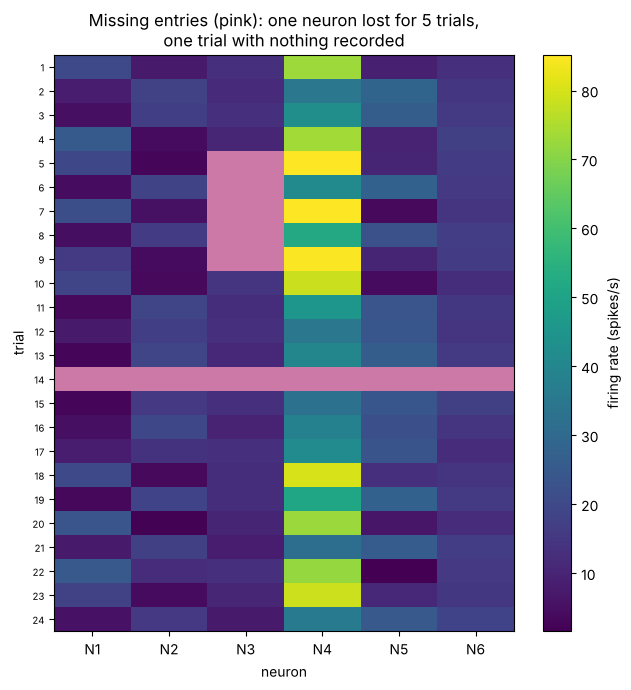

In [29]:
fig, ax = plt.subplots(figsize=(6.5, 7))
cmap = plt.get_cmap('viridis').copy()
cmap.set_bad(color=PALETTE[3])                          # missing entries drawn in pink
im = ax.imshow(np.ma.masked_invalid(rates_missing), aspect='auto', cmap=cmap)
ax.set_xticks(range(n_neurons)); ax.set_xticklabels(neuron_ids)
ax.set_yticks(range(n_trials)); ax.set_yticklabels(range(1, n_trials + 1), fontsize=7)
ax.set_xlabel('neuron'); ax.set_ylabel('trial')
ax.set_title('Missing entries (pink): one neuron lost for 5 trials,\none trial with nothing recorded')
fig.colorbar(im, ax=ax, label='firing rate (spikes/s)')
plt.tight_layout()
plt.show()

Three common responses, each with a cost:

| Strategy | Code | Cost |
|---|---|---|
| Drop incomplete **trials** | `X[~missing.any(axis=1)]` | lose every neuron's data on those trials |
| Drop incomplete **neurons** | `X[:, ~missing.any(axis=0)]` | lose that neuron entirely |
| **Impute** with the column mean | `np.where(missing, np.nanmean(X, 0), X)` | shrinks variability; invents values |

None is free, and the right choice depends on *why* data are missing. If an electrode drifts *because* the neuron is firing strongly, the missing values are not a random sample, and every strategy biases the result. Report what was missing and what you did about it.

In [30]:
complete_trials = ~missing.any(axis=1)
X_drop_trials = rates_missing[complete_trials]
X_drop_neuron = rates_missing[:, ~missing.any(axis=0)]
X_imputed = np.where(missing, np.nanmean(rates_missing, axis=0), rates_missing)

print("Drop trials :", X_drop_trials.shape, f" ({(~complete_trials).sum()} trials removed)")
print("Drop neurons:", X_drop_neuron.shape, " <- every neuron removed: the aborted trial is missing in all of them")
print("Impute      :", X_imputed.shape, " nan left?", np.isnan(X_imputed).any())

Drop trials : (18, 6)  (6 trials removed)
Drop neurons: (24, 0)  <- every neuron removed: the aborted trial is missing in all of them
Impute      : (24, 6)  nan left? False


Notice the second line: dropping incomplete *neurons* removes every neuron, because the aborted trial is missing in all of them. Usually you drop fully empty trials first, and only then decide about partially missing neurons. Order matters.

# **Part 9: Keeping Metadata Aligned**

The matrix does not store its own labels. The condition of each trial lives in `conditions`, a separate array, and the identity of each neuron in `neuron_ids`. They stay meaningful only while **row $i$ of the matrix and entry $i$ of the label array refer to the same trial.**

Any operation that reorders or removes rows (sorting, filtering, dropping missing trials, shuffling) must be applied to the labels in exactly the same way.

In [31]:
# Correct: compute ONE ordering and apply it to everything that has one entry per trial
order = np.argsort(conditions, kind='stable')     # all 'left' trials first, then 'right'
rates_sorted = rates[order]
conditions_sorted = conditions[order]
trial_numbers_sorted = np.arange(1, n_trials + 1)[order]

# Buggy: sort the matrix by something else, but forget the labels
order_by_N1 = np.argsort(rates[:, 0])
rates_bug = rates[order_by_N1]                    # labels NOT reordered

def condition_difference(X, labels):
    return X[labels == 'left'].mean(axis=0) - X[labels == 'right'].mean(axis=0)

print("Left minus right, aligned   :", condition_difference(rates_sorted, conditions_sorted).round(1))
print("Left minus right, misaligned:", condition_difference(rates_bug, conditions).round(1))
print("\nNo error was raised, but the misaligned difference is mostly noise: the labels no longer belong to their rows.")

Left minus right, aligned   : [ 15.4 -12.4   0.5  38.2 -16.8  -0.6]
Left minus right, misaligned: [-0.3  0.3 -0.6 -3.5  1.1  1.1]

No error was raised, but the misaligned difference is mostly noise: the labels no longer belong to their rows.


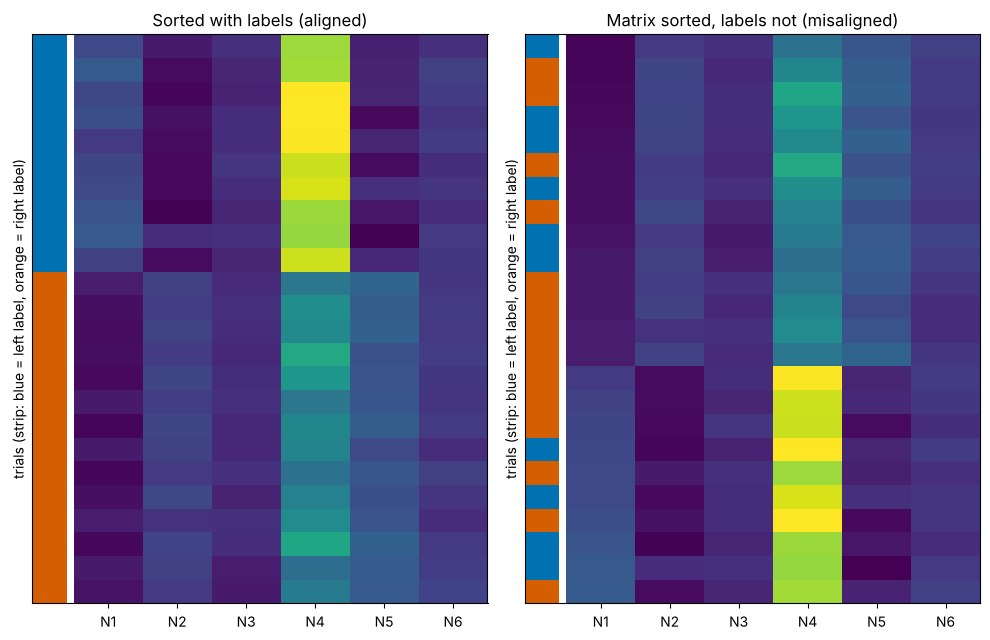

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(10, 6.5), gridspec_kw={'width_ratios': [1, 1]})
for ax, M, labs, title in [(axes[0], rates_sorted, conditions_sorted, 'Sorted with labels (aligned)'),
                           (axes[1], rates_bug, conditions, 'Matrix sorted, labels not (misaligned)')]:
    ax.imshow(M, aspect='auto', cmap='viridis')
    strip = np.array([[1.0] if c == 'left' else [0.0] for c in labs])
    ax.imshow(strip, extent=(-1.1, -0.6, n_trials - 0.5, -0.5), aspect='auto',
              cmap=plt.matplotlib.colors.ListedColormap([PALETTE[1], PALETTE[0]]))
    ax.set_xlim(-1.1, n_neurons - 0.5)
    ax.set_xticks(range(n_neurons)); ax.set_xticklabels(neuron_ids)
    ax.set_yticks([]); ax.set_ylabel('trials (strip: blue = left label, orange = right label)')
    ax.set_title(title)
plt.tight_layout()
plt.show()

On the left the label strip and the blocks of activity agree: N1 is bright exactly where the strip says "left". On the right the rows were reordered but the strip was not, so the labels describe the wrong trials.

### Letting pandas keep the labels for you

A `pandas.DataFrame` stores the matrix together with row and column labels, so sorting, filtering and grouping move the labels automatically. It is often the safest container for a dataset with metadata.

In [33]:
import pandas as pd

df = pd.DataFrame(rates, columns=neuron_ids)
df.insert(0, 'condition', conditions)
df.index = pd.Index(np.arange(1, n_trials + 1), name='trial')

print(df.head(4))
print("\nCondition means (the labels travel with the rows automatically):")
print(df.groupby('condition').mean().round(1))

      condition    N1    N2    N3    N4    N5    N6
trial                                              
1          left  20.2   7.8  13.2  73.1   9.1  13.1
2         right   8.2  17.9  11.5  34.6  28.7  14.7
3         right   4.9  17.1  13.3  42.9  26.2  15.9
4          left  25.4   4.0  10.7  73.5   9.8  17.3

Condition means (the labels travel with the rows automatically):
             N1    N2    N3    N4    N5    N6
condition                                    
left       20.9   5.0  12.0  78.4   7.9  14.8
right       5.5  17.4  11.4  40.2  24.7  15.4


# **Part 10: Mini-Lab — From a Raw Recording to Condition Averages**

This mini-lab combines the lesson into one analysis of a new, messier recording: 8 neurons, 60 trials, three conditions (left, right, and a no-go trial where the animal withholds a response), with missing values and trials in random order. It needs no internet access or external files.

**Your task, worked through below:**
1. Describe the matrix: shape, axis meaning, units, missing values.
2. Clean it: remove fully empty trials, then trials with missing values, keeping labels aligned.
3. Standardise each neuron (z-score each column).
4. Build the condition-average matrix (conditions × neurons).
5. Compare the conditions with the Lesson 2 cosine-similarity matrix.
6. Write a scientific interpretation and note a limitation.

In [34]:
# PROVIDED RECORDING -- generated reproducibly
lab_neurons = np.array([f'N{k}' for k in range(1, 9)])
lab_conditions_all = RNG.choice(np.array(['left', 'right', 'no-go']), size=60)
templates = {'left':  np.array([25.0,  6.0, 10.0, 70.0,  8.0, 12.0, 20.0, 15.0]),
             'right': np.array([ 7.0, 22.0, 10.0, 35.0, 24.0, 12.0, 20.0, 15.0]),
             'no-go': np.array([10.0, 10.0, 22.0, 30.0, 10.0, 25.0, 20.0, 15.0])}
lab_sd = np.array([3.0, 3.0, 3.0, 8.0, 3.0, 3.0, 3.0, 3.0])
lab_rates = np.clip(np.array([templates[c] + RNG.normal(0.0, lab_sd) for c in lab_conditions_all]), 0, None)

lab_rates[RNG.choice(60, size=3, replace=False), :] = np.nan                   # 3 aborted trials
lab_rates[RNG.choice(60, size=6, replace=False), RNG.integers(0, 8, 6)] = np.nan  # 6 scattered dropouts

# Step 1: describe
lab_missing = np.isnan(lab_rates)
print("lab_rates shape:", lab_rates.shape, " (n_trials, n_neurons), units: spikes/s")
print("Missing entries:", lab_missing.sum(), " | fully empty trials:", lab_missing.all(axis=1).sum(),
      " | trials with any missing:", lab_missing.any(axis=1).sum())

lab_rates shape: (60, 8)  (n_trials, n_neurons), units: spikes/s
Missing entries: 29  | fully empty trials: 3  | trials with any missing: 8


In [35]:
# Step 2: clean, applying the same row selection to the labels
keep = ~lab_missing.any(axis=1)                 # drop any trial with a missing value
X_clean = lab_rates[keep]
labels_clean = lab_conditions_all[keep]
print("After cleaning:", X_clean.shape, "| trials per condition:",
      ", ".join(f"{c} {int((labels_clean == c).sum())}" for c in ['left', 'right', 'no-go']))

# Step 3: standardise each neuron
X_z = (X_clean - X_clean.mean(axis=0)) / X_clean.std(axis=0)

# Step 4: condition-average matrix, shape (n_conditions, n_neurons)
cond_names = ['left', 'right', 'no-go']
cond_means = np.stack([X_z[labels_clean == c].mean(axis=0) for c in cond_names])
print("cond_means shape:", cond_means.shape, " (n_conditions, n_neurons), units: SDs")

# Step 5: cosine similarity between condition patterns (Lesson 2)
unit = cond_means / np.linalg.norm(cond_means, axis=1, keepdims=True)
cond_similarity = unit @ unit.T                  # every row dotted with every row
print("\nCosine similarity between condition patterns:")
print(pd.DataFrame(cond_similarity.round(2), index=cond_names, columns=cond_names))

After cleaning: (52, 8) | trials per condition: left 22, right 16, no-go 14
cond_means shape: (3, 8)  (n_conditions, n_neurons), units: SDs

Cosine similarity between condition patterns:
       left  right  no-go
left   1.00  -0.67  -0.61
right -0.67   1.00  -0.18
no-go -0.61  -0.18   1.00


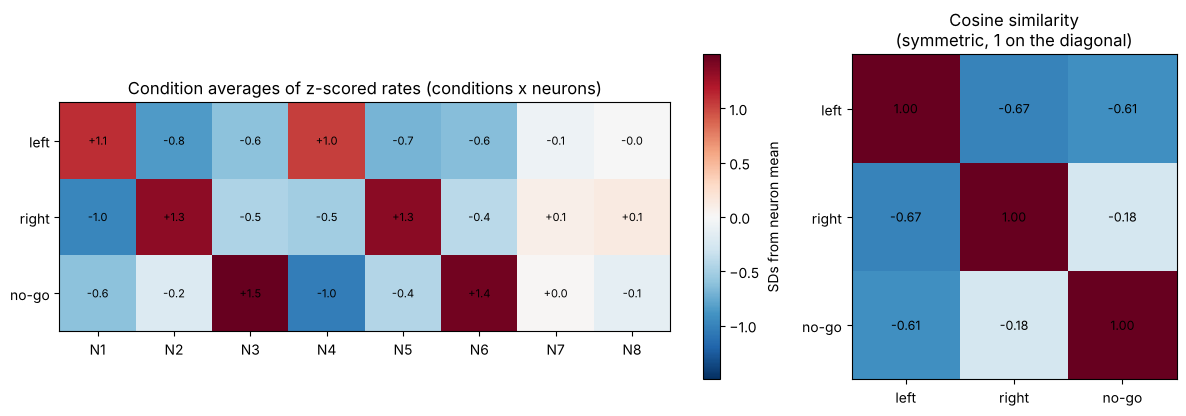

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={'width_ratios': [2, 1]})
ax = axes[0]
lim = np.abs(cond_means).max()
im = ax.imshow(cond_means, cmap='RdBu_r', vmin=-lim, vmax=lim)
ax.set_xticks(range(8)); ax.set_xticklabels(lab_neurons); ax.set_yticks(range(3)); ax.set_yticklabels(cond_names)
for (i, j), v in np.ndenumerate(cond_means):
    ax.text(j, i, f'{v:+.1f}', ha='center', va='center', fontsize=8)
ax.set_title('Condition averages of z-scored rates (conditions x neurons)')
fig.colorbar(im, ax=ax, fraction=0.03, label='SDs from neuron mean')
ax = axes[1]
im = ax.imshow(cond_similarity, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(3)); ax.set_xticklabels(cond_names); ax.set_yticks(range(3)); ax.set_yticklabels(cond_names)
for (i, j), v in np.ndenumerate(cond_similarity):
    ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=9)
ax.set_title('Cosine similarity\n(symmetric, 1 on the diagonal)')
plt.tight_layout()
plt.show()

**Interpretation:** after cleaning and z-scoring, each condition has a distinct signature across the population. Left trials drive N1 and N4, right trials drive N2 and N5, and no-go trials drive N3 and N6; N7 and N8 do not distinguish the conditions. Because the data are z-scored (centred per neuron), the condition patterns can be *opposite*, which raw firing rates could never show (Lesson 2, Part 6). The left pattern is anti-aligned with both others (about $-0.6$), because its strongest neurons are below average in the other two conditions. Right and no-go are close to orthogonal (about $-0.2$): they mostly drive different neurons.

**Limitation:** dropping every trial with any missing value discarded data that the other neurons recorded correctly; if dropouts were related to the condition, the remaining trials are no longer a fair sample. The z-scores were also computed from all trials together, which is fine for description but would be leakage if these averages were used to test a decoder.

# **Part 11: Summary and Lesson 4 Preview**

| Idea | Notation / code | What to remember |
|---|---|---|
| Matrix, shape | $\mathbf{X}\in\mathbb{R}^{m\times n}$, `X.shape` | rows first, then columns |
| Entry | $x_{ij}$, `X[i-1, j-1]` | row index first; Python counts from 0 |
| Row / column | `X[i]`, `X[:, j]` | a trial's state / a neuron across trials |
| Axis reduction | `X.mean(axis=0)` | the axis you name disappears |
| Transpose | $\mathbf{X}^{\mathsf T}$, `X.T` | $(\mathbf{X}^{\mathsf T})_{ij} = x_{ji}$; swaps the shape |
| Symmetric | $\mathbf{A}^{\mathsf T} = \mathbf{A}$ | distances, similarities, undirected networks |
| Adjacency | $a_{ij}$ = weight from $j$ to $i$ | row = inputs, column = outputs; state the convention |
| Hadamard product | $\mathbf{A}\odot\mathbf{B}$, `A * B` | entry by entry, same shapes |
| Matrix product | `A @ B` | rows dotted with columns (Lesson 4) |
| Z-score | $(x_{ij}-\mu_j)/s_j$ | per column; statistics from training data only |
| Missing data | `np.nan`, `np.nanmean` | missing is not zero; report what you did |
| Metadata | `X[order]`, `labels[order]` | reorder rows and labels together |

**Lesson 4** turns the `@` of Part 6 into the central operation of linear algebra. A matrix becomes a *transformation* that maps one vector space to another: multiplying the adjacency matrix by a population vector gives every neuron's total input at once, and a layer of a neural network is a matrix followed by a nonlinearity.